# Single Sided LBTI-NOMIC Data

This notebook is for pre-processing of single-sided LBTI-NOMIC data starting from the raw data.

In [1]:
# Forces OpenBLAS to single threads to allow for multiprocessing
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
print("CPUS: ", os.cpu_count())
import multiprocessing

# Set spawn as multiprocessing method
if __name__ == '__main__':
    multiprocessing.set_start_method('spawn')

CPUS:  192


In [2]:
import pyNOMIC.preprocessing as prep
import pyNOMIC.data_setup as ds
import pyNOMIC.helper_functions as hf
import pyNOMIC.frame_evaluation as fe
import shutil, pathlib, os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from tqdm.auto import tqdm

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


### File path

Enter directory containing raw files, the name of the star as it exists in the FITS headers, and its approximate temperature (for PSF fitting).

In [3]:
raw_dir = "raw"
obj='Procyon'
stellar_temp = 6582

# Important to sort the data for reading it sequentially
raw_files = sorted(list(pathlib.Path(str(raw_dir)).rglob('*.fits')))
raw_files = np.asarray([a for a in raw_files if a.name[0]!='.' and str(a.parent)==raw_dir])

DATE-OBS:  2022-02-19


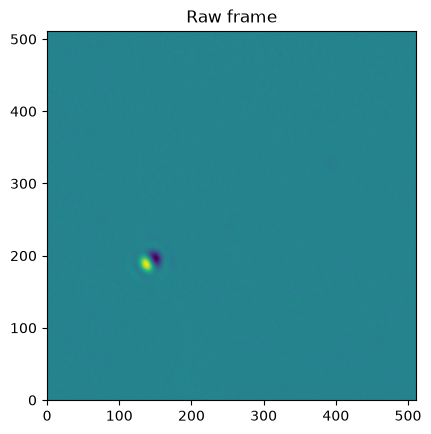

In [5]:
hdul = fits.open(raw_files[0])
hdul2 = fits.open(raw_files[3])
print("DATE-OBS: ", hdul[0].header["DATE-OBS"])
plt.title("Raw frame")
plt.imshow((hdul[0].data[0] - hdul2[0].data[0]), origin="lower")
hdul.close()
hdul2.close()
plt.show()


### Get header data and parallactic angles

We use the `setup_data` function to obtain frame medians and parallactic angles. The chop states from the headers are also retrieved, but are usually not useful. The images/masks from earlier are inputs into this function. Frames above the default frame median limit are discarded.

In [6]:
# Retrieve from npz
combined_data = np.load(obj+"_NOMIC_setupdata.npz", allow_pickle=True)
uncorrected_files = combined_data["arr_0"]
uncorrected_chops = combined_data["arr_1"]
uncorrected_header_info = combined_data["arr_2"]
print("File retrieved")

File retrieved


### Create badmap, temporary flat, and highpass filter mask

We first create a badmap to filter out dead pixels/columns, a temporary flat for use in chop state identification, and a highpass filter mask to avoid edge artifacts. The highpass filter mask *must* include the regions where the PSF is.

In [7]:
hdul = fits.open(obj+"_tempflat.fits")
tempflat = hdul[0].data
hdul.close()
hdul = fits.open(obj+"_badmap.fits")
badmap = hdul[0].data
hdul.close()

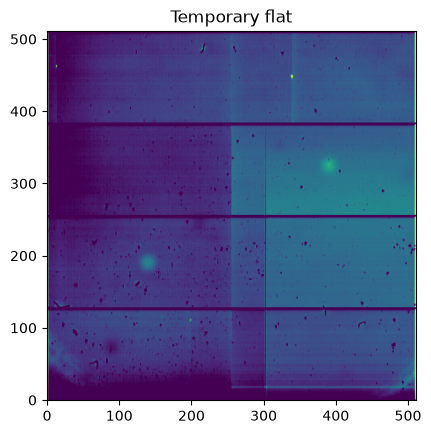

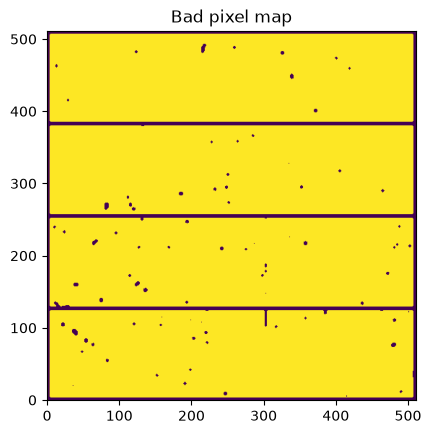

In [8]:
plt.title("Temporary flat")
plt.imshow(tempflat, origin="lower", vmin=14000, vmax=21000)
plt.show()

plt.title("Bad pixel map")
plt.imshow(badmap, origin="lower")
plt.show()

In [9]:
# We create the high pass filter mask here
highpassmask = np.ones(np.shape(badmap))
highpassmask[:120,:] = 0
highpassmask[400:,:] = 0
highpassmask[:,450:] = 0
highpassmask[:,:100] = 0

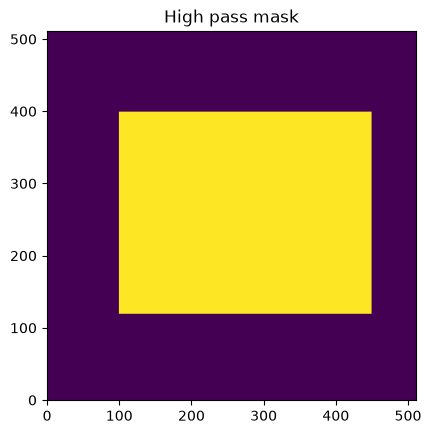

In [10]:
plt.title("High pass mask")
plt.imshow(highpassmask, origin="lower")
plt.show()

### Identify chops and create coadded frames

We identify the chop states of all the raw images using the frame medians and coadd any consecutive chops as necessary. We also edit our file list and parallactic angles to match the list. The coadded frames are saved in a separate directory and the file list is amended to include the coadded frames and exclude the parent raw frames.

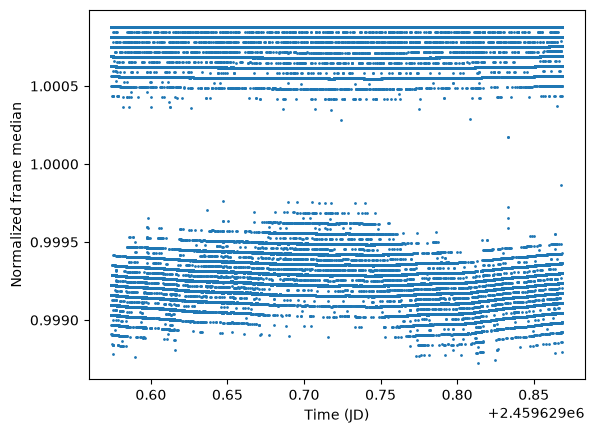

Number of frames in CHOP A:  115542
Number of frames in CHOP B:  113750


In [11]:
uncorrected_chops,_,chopm = ds.frame_med_chop_identification(uncorrected_header_info[0])

plt.scatter(uncorrected_header_info[2], chopm, s=1)
plt.xlabel("Time (JD)")
plt.ylabel("Normalized frame median")
plt.show()

print("Number of frames in CHOP A: ", len(uncorrected_chops[uncorrected_chops == "CHOP_A"]))
print("Number of frames in CHOP B: ", len(uncorrected_chops[uncorrected_chops == "CHOP_B"]))

In [12]:
# Retrieve from npz
chop_corrected_data = np.load(obj+"_NOMIC_chop_correction.npz", allow_pickle=True)
files = chop_corrected_data["arr_0"]
chops = chop_corrected_data["arr_1"]
header_info = chop_corrected_data["arr_2"]
print("Files retrieved")

Files retrieved


### Create more flats!

The temporary flat we created earlier was a good proxy for identifying chop states, but now that we have the chop states, we can construct a better flat that omits the stellar PSF for each chop state. First, we create a "combined" flat with the function `create_stacked_flat` that uses the halves of the image from each chop state that do not have the stellar PSF and stitch them together into a single flat for the whole dataset. This flat is used to help the function `subtract_psfs` create versions of the frames without the PSF.

In [13]:
hdul = fits.open(obj+"_combinedflat.fits")
combined_flat = hdul[0].data
hdul.close()

hdul = fits.open(obj+"_chopa_part.fits")
chopa_part = hdul[0].data
hdul.close()

hdul = fits.open(obj+"_chopb_part.fits")
chopb_part = hdul[0].data
hdul.close()
print("Flat retrieved")

Flat retrieved


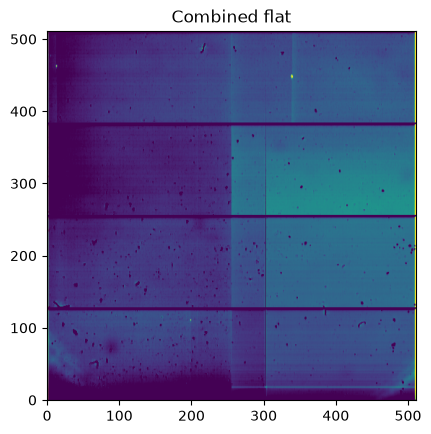

In [14]:
plt.title("Combined flat")
plt.imshow(combined_flat, origin="lower", vmin=14000, vmax=21000)
plt.show()

### Subtract PSFs to aid background subtraction/calibration

We can now model and subtract the PSF from the images to create even better flats for each chop state. We can also use these PSF subtracted images for chop subtraction.

##### Star masking
First, we create masks identifying the location of the star to ensure the PSF is located in its proper position.

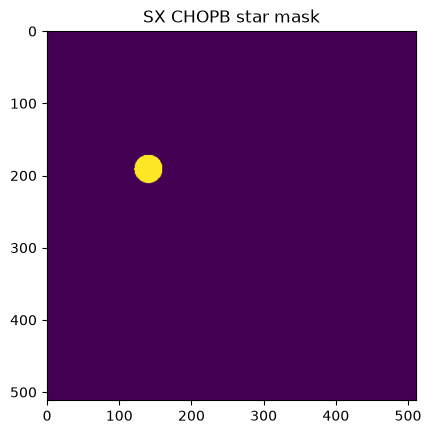

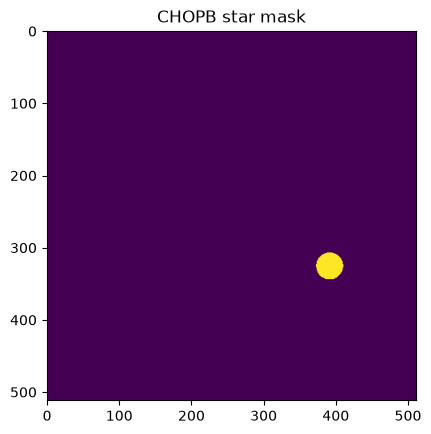

In [16]:
(chopa_starmask,
 chopb_starmask) = prep.create_star_mask(chopa_part, chopb_part, combined_flat, combined_flat,
                                         badmap, highpassmask, sigma=6, growth=10)

plt.title("SX CHOPB star mask")
plt.imshow(chopa_starmask)
plt.show()

plt.title("CHOPB star mask")
plt.imshow(chopb_starmask)
plt.show()

In [18]:
# Retrieve from npz
psf_subtracted_data = np.load(obj+"_NOMIC_psf_subtraction.npz", allow_pickle=True)
psf_subtracted_files = psf_subtracted_data["arr_0"]
maxima = psf_subtracted_data["arr_1"]
failcodes = psf_subtracted_data["arr_2"]
print("Files retrieved")

Files retrieved


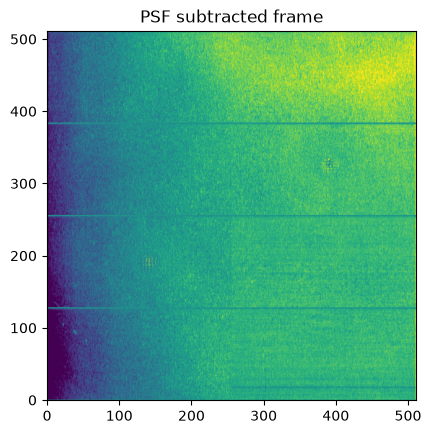

In [20]:
num = 38804
hdul = fits.open(psf_subtracted_files[num])
hdul2 = fits.open(psf_subtracted_files[num+1])
img = hdul[0].data - hdul2[0].data
hdul.close()
hdul2.close()

plt.title("PSF subtracted frame")
plt.imshow(img, origin="lower", vmin=-150, vmax=150)
plt.show()

### Monitor star positions and background positions

We can use the function hf.image_groups to look for portions of the dataset that are noticeably shifted from the rest of the dataset and remove them to ensure that we adequately correct chop residuals. We can then likewise measure the positions of the background and align the backgrounds together and avoid smaller shifts in the chop residuals.

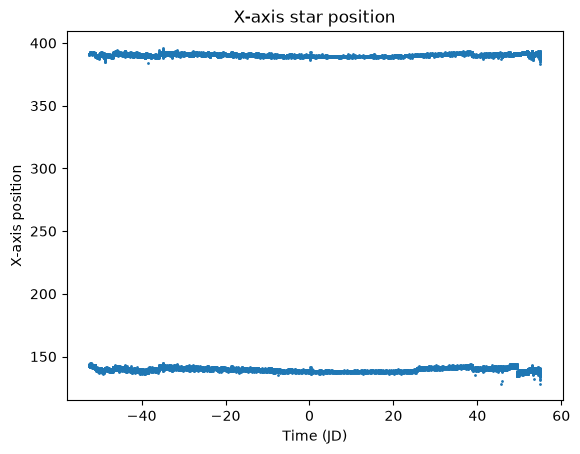

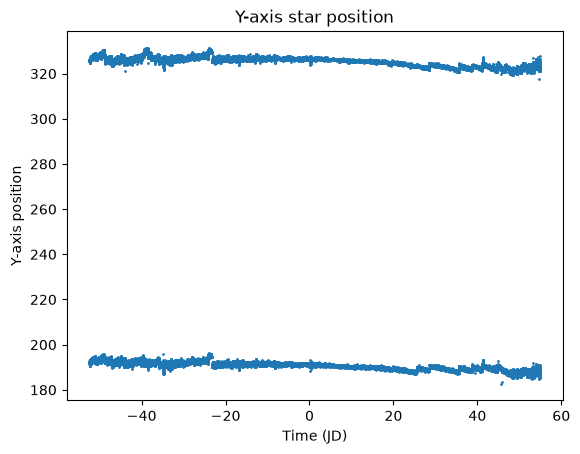

In [21]:
plt.scatter(header_info[1], maxima[:,1], s=1)
plt.xlabel("Time (JD)")
plt.ylabel("X-axis position")
plt.title("X-axis star position")
plt.show()

plt.scatter(header_info[1], maxima[:,0], s=1)
plt.xlabel("Time (JD)")
plt.ylabel("Y-axis position")
plt.title("Y-axis star position")
plt.show()

Image groups: 
Image group 0:  0.08399328053755699
Image group 1:  2.7432805375569953
Image group 2:  3.7931965442764577
Image group 3:  2.3600611951043917
Image group 4:  3.571964242860571
Image group 5:  7.8188744900407965
Image group 6:  7.652387808975282
Image group 7:  0.43271538276937843
Image group 8:  25.266228701703863
Image group 9:  4.8078653707703385
Image group 10:  2.5505459563234942
Image group 11:  2.1005819534437244
Image group 12:  3.9131869450443966
Image group 13:  5.679295656347493
Image group 14:  2.9832613390928726
Image group 15:  2.963012958963283
Image group 16:  1.771358291336693
Image group 17:  5.100341972642188
Image group 18:  3.7489500839932806
Image group 19:  2.7530297576193905
Image group 20:  1.7151127909767219
Image group 21:  6.13300935925126
Image group 22:  0.057745380369570436


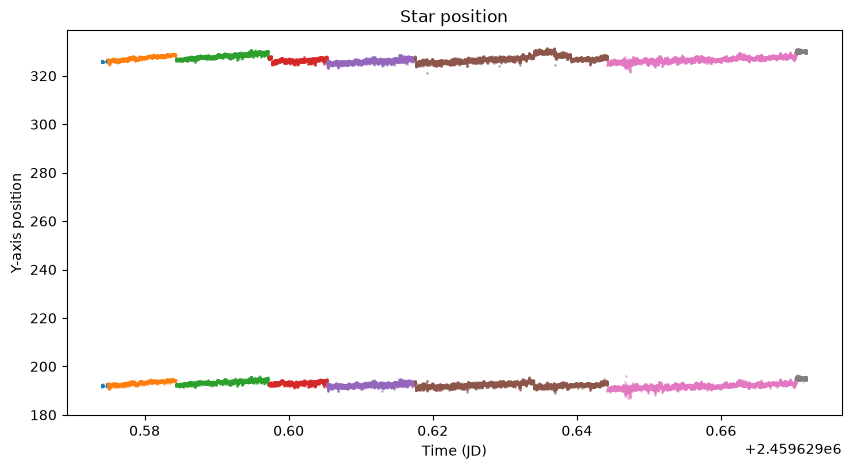

In [22]:
img_group_times, img_group_pos = hf.image_groups(header_info[2], maxima[:,0])

plt.figure(figsize=(10,5), dpi=100)

plt.scatter(img_group_times[0], img_group_pos[0], s=1, alpha=0.4)
plt.scatter(img_group_times[1], img_group_pos[1], s=1, alpha=0.4)
plt.scatter(img_group_times[2], img_group_pos[2], s=1, alpha=0.4)
plt.scatter(img_group_times[3], img_group_pos[3], s=1, alpha=0.4)
plt.scatter(img_group_times[4], img_group_pos[4], s=1, alpha=0.4)
plt.scatter(img_group_times[5], img_group_pos[5], s=1, alpha=0.4)
plt.scatter(img_group_times[6], img_group_pos[6], s=1, alpha=0.4)
plt.scatter(img_group_times[7], img_group_pos[7], s=1, alpha=0.4)

plt.xlabel("Time (JD)")
plt.ylabel("Y-axis position")
plt.title("Star position")
plt.show()

### Perform chop alignment

We can now align the chop residuals together to measure their offsets over time and to construct a flat to remove them in background subtraction. We first measure these offsets, perform a median filter to remove random noise, and then perform the alignment.

In [ ]:
(_,
 _,
 _,
 _,
 chop_offsets,
 _) = prep.chop_align(psf_subtracted_files, chops, maxima=maxima,
                      save_file=False, parallel_mode = "processors")

In [ ]:
from scipy.ndimage import median_filter
median_chop_offsets = np.copy(chop_offsets)
median_chop_offsets[:,0] = median_filter(chop_offsets[:,0],  size=7)
median_chop_offsets[:,1] = median_filter(chop_offsets[:,1],  size=7)

plt.scatter(header_info[2], chop_offsets[:,0], s=1, alpha=0.1)
plt.plot(header_info[2], median_chop_offsets[:,0], alpha=0.5)
plt.xlabel("Time (JD)")
plt.ylabel("X chop offset")
plt.show()

plt.scatter(header_info[2], chop_offsets[:,1], s=1, alpha=0.1)
plt.plot(header_info[2], median_chop_offsets[:,1], alpha=0.5)
plt.xlabel("Time (JD)")
plt.ylabel("Y chop offset")
plt.show()

In [ ]:
(chopres_files,
 highfreq_files,
 chopres_stds,
 highfreq_stds,
 chop_offsets,
 prefit_offsets) = prep.chop_align(psf_subtracted_files, chops, maxima=maxima,
                                   registration_method=None, save_file=True,
                                   offsets=median_chop_offsets,
                                   parallel_mode="threads")

np.savez(obj+"_NOMIC_chop_alignment.npz", chopres_files, highfreq_files,
         chopres_stds, highfreq_stds, chop_offsets, median_chop_offsets)
print("Files saved")

### Create flats for each chop state

In [ ]:
(_,
 chopresa_flat,
 chopresb_flat) = prep.create_stacked_flat(chopres_files, chops,
                                           chop_direction="UP-DOWN", tolerance=0.1)

(_,
 chopresa_flat,
 chopresb_flat) = prep.create_stacked_flat(chopres_files, chops,
                                           chop_direction="UP-DOWN", tolerance=0.1)
(_,
 highfreqa_flat,
 highfreqb_flat) = prep.create_stacked_flat(highfreq_files, chops,
                                            chop_direction="UP-DOWN", tolerance=0.1)

(_,
 highfreqa_flat,
 highfreqb_flat) = prep.create_stacked_flat(highfreq_files, chops,
                                            chop_direction="UP-DOWN", tolerance=0.1)

(_,
 chopa_flat,
 chopb_flat) =\
        prep.create_stacked_flat(psf_subtracted_files, chops,
                                 chop_direction="UP-DOWN", tolerance=0.1)

hdul = fits.HDUList([fits.PrimaryHDU(data=chopa_flat)])
hdul.writeto(obj+"_chopa_flat.fits", overwrite=True)
hdul.close()
 
hdul = fits.HDUList([fits.PrimaryHDU(data=chopb_flat)])
hdul.writeto(obj+"_chopb_flat.fits", overwrite=True)
hdul.close()

hdul = fits.HDUList([fits.PrimaryHDU(data=chopresa_flat)])
hdul.writeto(obj+"_chopresa_flat.fits", overwrite=True)
hdul.close()
 
hdul = fits.HDUList([fits.PrimaryHDU(data=chopresb_flat)])
hdul.writeto(obj+"_chopresb_flat.fits", overwrite=True)
hdul.close()

hdul = fits.HDUList([fits.PrimaryHDU(data=highfreqa_flat)])
hdul.writeto(obj+"_highfreqa_flat.fits", overwrite=True)
hdul.close()
 
hdul = fits.HDUList([fits.PrimaryHDU(data=highfreqb_flat)])
hdul.writeto(obj+"_highfreqb_flat.fits", overwrite=True)
hdul.close()

hdul = fits.open(obj+"_chopa_flat.fits")
chopa_flat = hdul[0].data
hdul.close()
hdul = fits.open(obj+"_chopb_flat.fits")
chopb_flat = hdul[0].data
hdul.close()

### Background subtraction

We now create background subtracted (and flat calibrated) images, with some image repair as well to deal with NOMIC systematics (striped regions, biases). These images are saved in a directory.

In [18]:
reduced_data = np.load(obj+"_NOMIC_subtracted.npz", allow_pickle=True)
chopsub_stds = reduced_data["arr_0"]
backsub_stds = reduced_data["arr_1"]
subtracted_dir = str(reduced_data["arr_2"])
print("Files retrieved")

Files retrieved


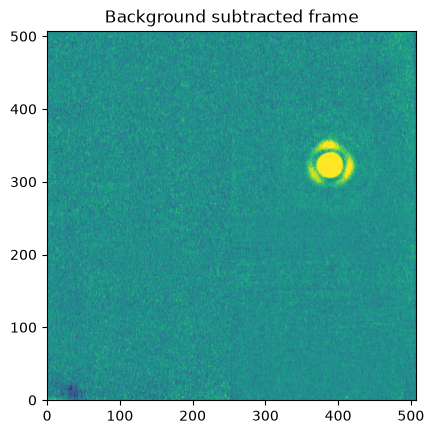

In [19]:
# Important to sort the data for reading it sequentially
subtracted_files = sorted(list(pathlib.Path(str(subtracted_dir))\
                       .rglob('*.fits')))
subtracted_files = np.asarray([a for a in subtracted_files\
                                   if a.name[0]!='.'\
                                   and str(a.parent)==subtracted_dir])

hdul = fits.open(subtracted_files[28453])
img = hdul[0].data
hdul.close()

plt.title("Background subtracted frame")
plt.imshow(img, origin="lower", vmin=-100, vmax=100)
plt.show()

### Frame registration
We now align the frames and place the PSFs at the center of the image. We obtain other parameters as well, including image characteristics and gaussian model fits.

In [13]:
reduced_data = np.load(obj+"_NOMIC_aligned.npz", allow_pickle=True)
aligned_files = reduced_data["arr_0"]
original_psf_locs = reduced_data["arr_1"]
imgfits = reduced_data["arr_2"]
array_shape = reduced_data["arr_3"]
file_size = reduced_data["arr_4"]
print("Files retrieved")

Files retrieved


## Mask out the oversubtracted PSF from the aligned files

In [21]:
aligned_files = np.asarray(sorted(list(pathlib.Path("masked")\
                 .rglob('*.fits'))))

133344


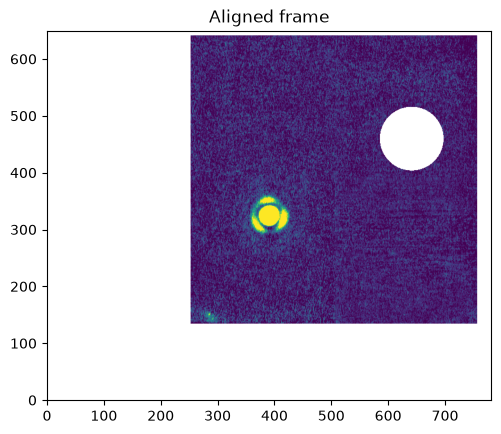

In [22]:
print(len(aligned_files))
plt.title("Aligned frame")
hdul = fits.open(aligned_files[50050])
plt.imshow(hdul[0].data, vmin=-10, vmax=100, origin="lower")
hdul.close()
plt.show()

### Frame evaluation
We now evaluate the frames to get properties including fwhms, background deviation, maxima, etc.

In [ ]:
evaluations = np.load(obj+"_NOMIC_evaluated.npz", allow_pickle=True)

fwhms = evaluations["arr_0"]
eccentricities = evaluations["arr_1"]
psfmaxima = evaluations["arr_2"]
background_dev = evaluations["arr_3"]
psf_dev = evaluations["arr_4"]
correlations = evaluations["arr_5"]
residual_dev = evaluations["arr_6"]
lbtfits = evaluations["arr_7"]
reffits = evaluations["arr_8"]
print("Files retrieved")

### Frame rejection and binning
We can do a first round of rejection using frame properties, and then bin the frames and obtain the binned frame properties.

In [24]:
frame_bool = fe.frame_rejection(chops,
                                [fwhms, eccentricities])
print("Percent of frames kept: ",
      100*len(frame_bool[frame_bool == True])/len(frame_bool))

Percent of frames kept:  90.83273338132949


In [17]:
binned_evaluations = np.load(obj+"_NOMIC_binned_evaluated.npz", allow_pickle=True)

binned_fwhms = binned_evaluations["arr_0"]
binned_eccs = binned_evaluations["arr_1"]
binned_psfmax = binned_evaluations["arr_2"]
binned_backdev = binned_evaluations["arr_3"]
binned_psfdev = binned_evaluations["arr_4"]
binned_corrs = binned_evaluations["arr_5"]
binned_resdev = binned_evaluations["arr_6"]
binned_lbtfits= binned_evaluations["arr_7"]
binned_reffits = binned_evaluations["arr_8"]
binned_files = binned_evaluations["arr_9"]
binned_chops = binned_evaluations["arr_10"]
binned_angles = binned_evaluations["arr_11"]
print("Files retrieved")

Files retrieved


In [18]:
binned_frames = np.zeros((len(binned_files), array_shape[0], array_shape[1]))
for i in tqdm(range(len(binned_files))):
    hdul = fits.open(binned_files[i])
    binned_frames[i] = hdul[0].data
    hdul.close()

  0%|          | 0/607 [00:00<?, ?it/s]

### Injection and PCA
We can inject a source into the image cube and perform PCA to recover the source.

In [92]:
from pyNOMIC.contrast_estimation import inject_source

injected_frames, injected_shape = inject_source(binned_frames,
                                                binned_angles, binned_reffits,
                                                array_shape, injection_radius = 35,
                                                injection_angle=180, contrast=2e-4,
                                                highpassrad=10, crop_size=150)

In [ ]:
(chopa_cube,
 der_chopa_cube,
 injected_med_image_chopa) = pca_annular(injected_frames[binned_chops == "CHOP_A"][1:-10],
                                         binned_angles[binned_chops == "CHOP_A"][1:-10],
                                         verbose=False, ncomp=3, fwhm=13, delta_rot=.1,
                                         radius_int=20, asize=30, nproc=1, svd_mode='eigen',
                                         imlib='opencv', collapse='median', full_output=True, cxy=(74.5, 74.5),
                                         max_frames_lib=len(injected_frames[binned_chops == "CHOP_A"][1:-10]))

(chopb_cube,
 der_chopb_cube,
 injected_med_image_chopb) = pca_annular(injected_frames[binned_chops == "CHOP_B"][1:-10],
                                         binned_angles[binned_chops == "CHOP_B"][1:-10],
                                         verbose=False, ncomp=3, fwhm=13, delta_rot=.1,
                                         radius_int=20, asize=30, nproc=1, svd_mode='eigen',
                                         imlib='opencv', collapse='median', full_output=True, cxy=(74.5, 74.5),
                                         max_frames_lib=len(injected_frames[binned_chops == "CHOP_B"][1:-10]))

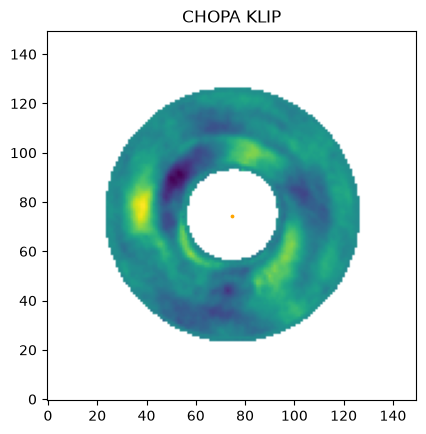

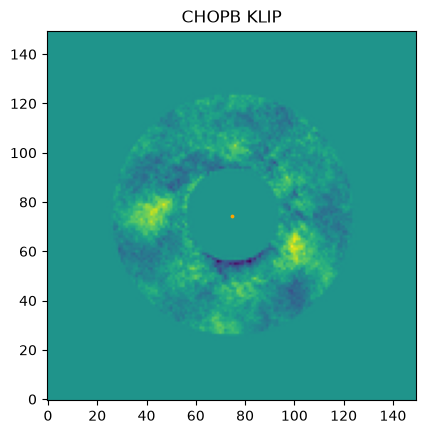

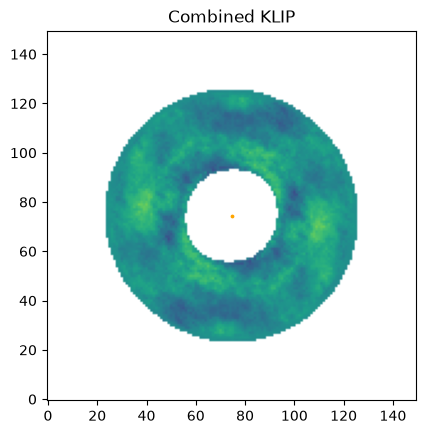

In [101]:
plt.title("CHOPA KLIP")
plt.imshow(injected_med_image_chopa, origin="lower")
plt.scatter(74.5, 74.5, s=3,color="orange")
plt.show()

plt.title("CHOPB KLIP")
plt.imshow(injected_med_image_chopb, origin="lower")
plt.scatter(74.5, 74.5, s=3,color="orange")
plt.show()

plt.title("Combined KLIP")
plt.imshow(injected_med_image_chopa + injected_med_image_chopb+np.rot90(injected_med_image_chopa + injected_med_image_chopb, k=2), vmin=-1e-2, vmax=1e-2, origin="lower")
plt.scatter(74.5, 74.5, s=3,color="orange")
plt.show()